In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

from pydub import AudioSegment
from scipy.signal import butter, sosfiltfilt

In [9]:
input_file = "audio1.mp3"
output_folder = "output"

os.makedirs(output_folder, exist_ok=True)

audio = (
    AudioSegment.from_mp3(input_file)
    .set_sample_width(2)
    .set_frame_rate(44100)
)

sampling_frequency = audio.frame_rate
channels = audio.channels

samples = np.array(audio.get_array_of_samples(), dtype=np.float64)
samples = samples.reshape(-1, channels)

original_signal = samples / 32768.0

print("Song loaded successfully!")
print("Sampling frequency:", sampling_frequency, "Hz")
print("Number of channels:", channels)
print("Duration:", len(original_signal) / sampling_frequency, "seconds")

Song loaded successfully!
Sampling frequency: 44100 Hz
Number of channels: 2
Duration: 27.539977324263038 seconds


In [10]:
def save_mp3(signal, filename):
    
    peak = np.max(np.abs(signal))

    if peak > 0:
        signal = signal * (0.98 / peak)

    signal = np.clip(signal, -1, 1)

    pcm = (signal * 32767).astype(np.int16)

    audio_segment = AudioSegment(
        data=pcm.tobytes(),
        sample_width=2,
        frame_rate=sampling_frequency,
        channels=channels
    )

    path = os.path.join(output_folder, filename)

    audio_segment.export(
        path,
        format="mp3",
        bitrate="192k"
    )

    print("Saved:", path)

In [11]:
def plot_audio(signal, title):
    number_of_samples = min(
        int(0.05 * sampling_frequency), len(signal)
    )

    time = np.arange(number_of_samples) / sampling_frequency

    plt.figure(figsize=(10, 3))
    plt.plot(time, signal[:number_of_samples, 0])
    plt.title(title + " - Time Domain")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    spectrum = np.abs(np.fft.rfft(signal[:, 0]))
    frequency = np.fft.rfftfreq(
        len(signal), d=1 / sampling_frequency
    )

    magnitude_db = 20 * np.log10(
        spectrum / (np.max(spectrum) + 1e-12) + 1e-12
    )

    plt.figure(figsize=(10, 3))
    plt.plot(frequency, magnitude_db)
    plt.title(title + " - Frequency Domain")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB, relative)")
    plt.xlim(0, min(10000, sampling_frequency / 2))
    plt.ylim(-100, 5)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Saved: output\butterworth_500Hz.mp3


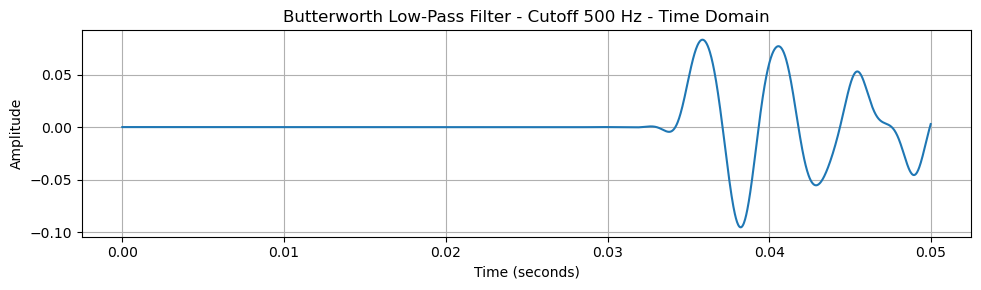

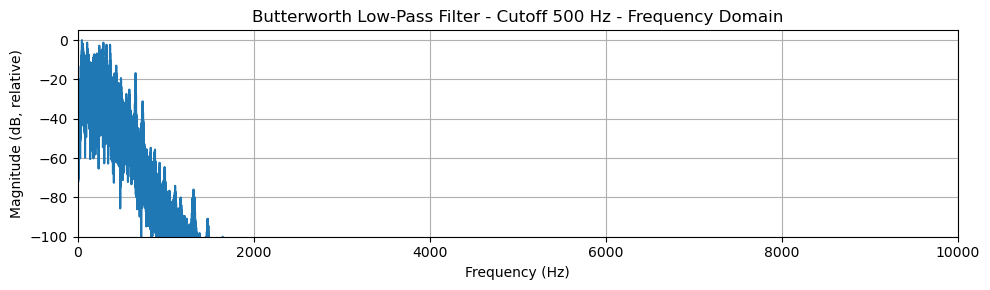

Saved: output\butterworth_1500Hz.mp3


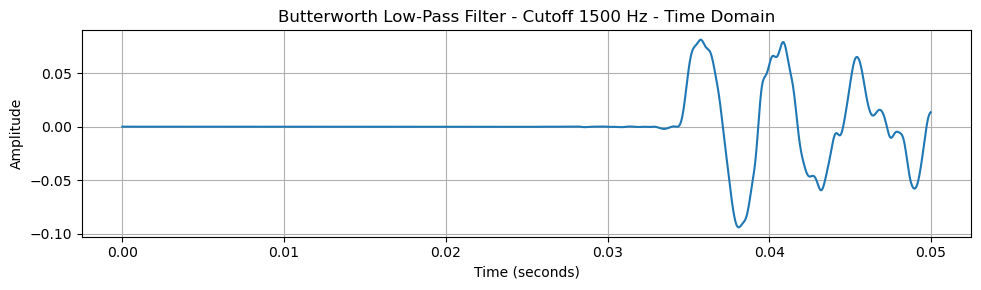

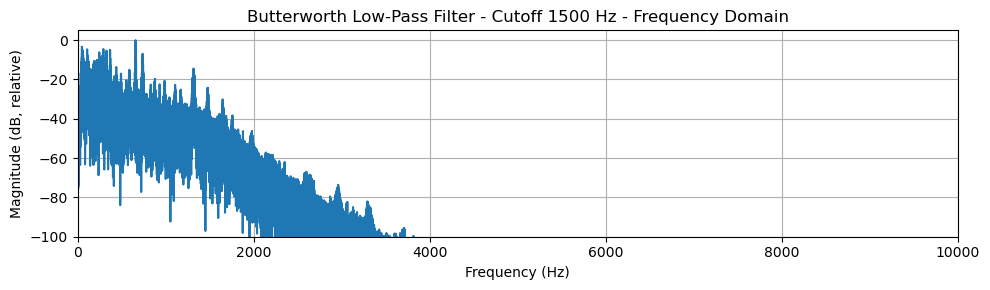

Saved: output\butterworth_4000Hz.mp3


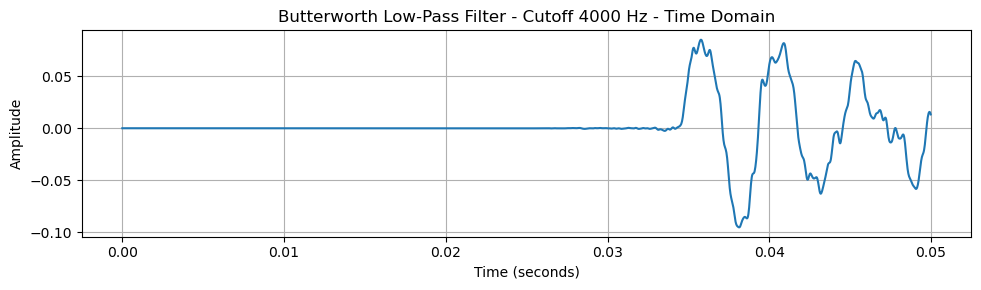

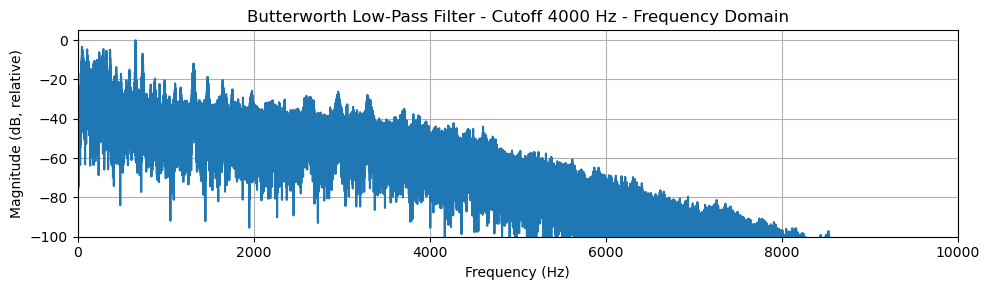

In [12]:
# Q3(a): BUTTERWORTH LOW-PASS FILTER

cutoff_frequencies = [500, 1500, 4000]

for cutoff in cutoff_frequencies:

    sos = butter(
        4,
        cutoff,
        btype="lowpass",
        fs=sampling_frequency,
        output="sos"
    )

    filtered_signal = sosfiltfilt(
        sos, original_signal, axis=0
    )

    filename = f"butterworth_{cutoff}Hz.mp3"

    save_mp3(filtered_signal, filename)

    plot_audio(
        filtered_signal,
        f"Butterworth Low-Pass Filter - Cutoff {cutoff} Hz"
    )

Saved: output\vocal_dominant.mp3


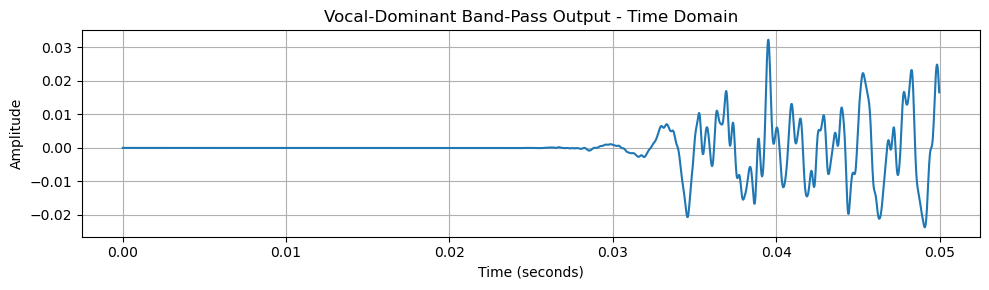

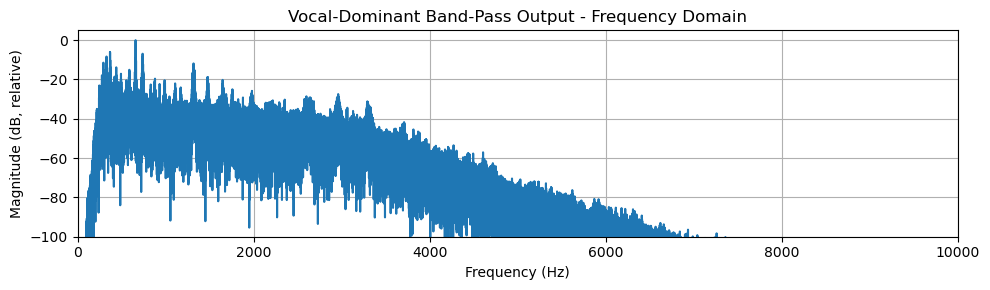

In [13]:
# Q3(b): VOCAL-DOMINANT BAND-PASS FILTER


vocal_low = 300
vocal_high = 3400

sos_vocal = butter(
    4,
    [vocal_low, vocal_high],
    btype="bandpass",
    fs=sampling_frequency,
    output="sos"
)

vocal_signal = sosfiltfilt(
    sos_vocal, original_signal, axis=0
)

save_mp3(vocal_signal, "vocal_dominant.mp3")

plot_audio(
    vocal_signal,
    "Vocal-Dominant Band-Pass Output"
)

Saved: output\high_frequency_music.mp3


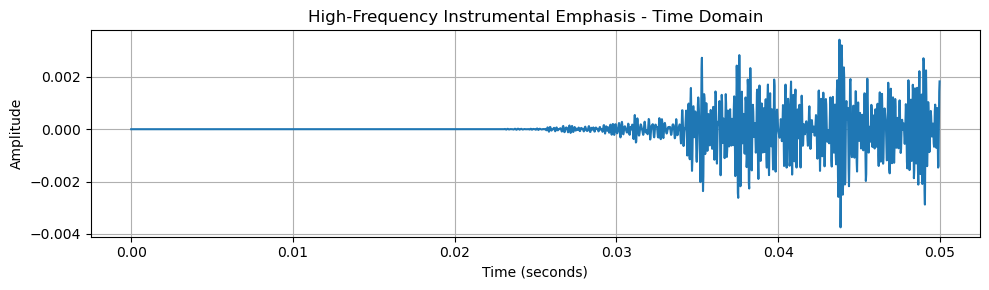

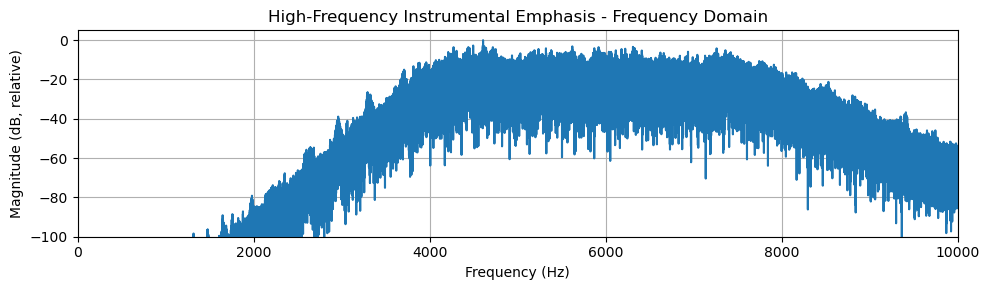

In [14]:
# Q3(b): HIGH-FREQUENCY INSTRUMENTAL EMPHASIS

music_low = 4000
music_high = min(
    8000, sampling_frequency / 2 - 100
)

sos_music = butter(
    4,
    [music_low, music_high],
    btype="bandpass",
    fs=sampling_frequency,
    output="sos"
)

music_signal = sosfiltfilt(
    sos_music, original_signal, axis=0
)

save_mp3(music_signal, "high_frequency_music.mp3")

plot_audio(
    music_signal,
    "High-Frequency Instrumental Emphasis"
)
